# EDA: что содержат 10 пар «чертёж — STL»

## Кратко

**Вход** — один PNG с видами, размерами и пояснениями. **Ожидаемый выход** — геометрия
детали в STL, в миллиметрах. Исследуем выбранные 10 пар: достаточно ли информации
во входах, насколько различаются формы и размеры, можно ли использовать сетки для сравнения.

Источник — учебные примеры КОМПАС-3D.

В исходной описи 27 пар; здесь анализируем только локальные 10. Набор отобран вручную,
все объекты относятся к валидации (`val`). Отдельной отладочной выборки пока нет.

Ниже только **исходные данные и эталоны**. Результаты запусков агента и его метрики
в этот анализ не входят. Данные читаются из [манифеста](../data/manifest.json);
запуск ноутбука не изменяет файлы набора и не обращается к API.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import trimesh
from IPython.display import Markdown, display
from matplotlib.colors import LightSource
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from PIL import Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/manifest.json").is_file())
DATA = ROOT / "data"
manifest = json.loads((DATA / "manifest.json").read_text(encoding="utf-8"))
items = {item["pair_id"]: item for item in manifest["items"]}
assert len(items) == 10 and all(item["split"] == "val" for item in items.values())
for item in items.values():
    for key in ("input_png", "target_mesh"):
        file = item[key]
        assert hashlib.sha256((DATA / file["path"]).read_bytes()).hexdigest() == file["sha256"], file["path"]

plt.rcParams.update({"font.size": 11, "figure.dpi": 150, "figure.facecolor": "white"})
print(f"Доступны {len(items)} пар. Контрольные суммы PNG и STL совпадают с описью.")

Доступны 10 пар. Контрольные суммы PNG и STL совпадают с описью.


## 1. Вход: общий вид чертежей

Одна галерея **4–4–2** показывает состав и компоновку листов. Масштаб миниатюр выбран
для обзора; мелкие размеры следует читать в оригиналах по ссылкам под галереей.
Цвета, пропорции и весь лист сохранены, обрезки видов нет.

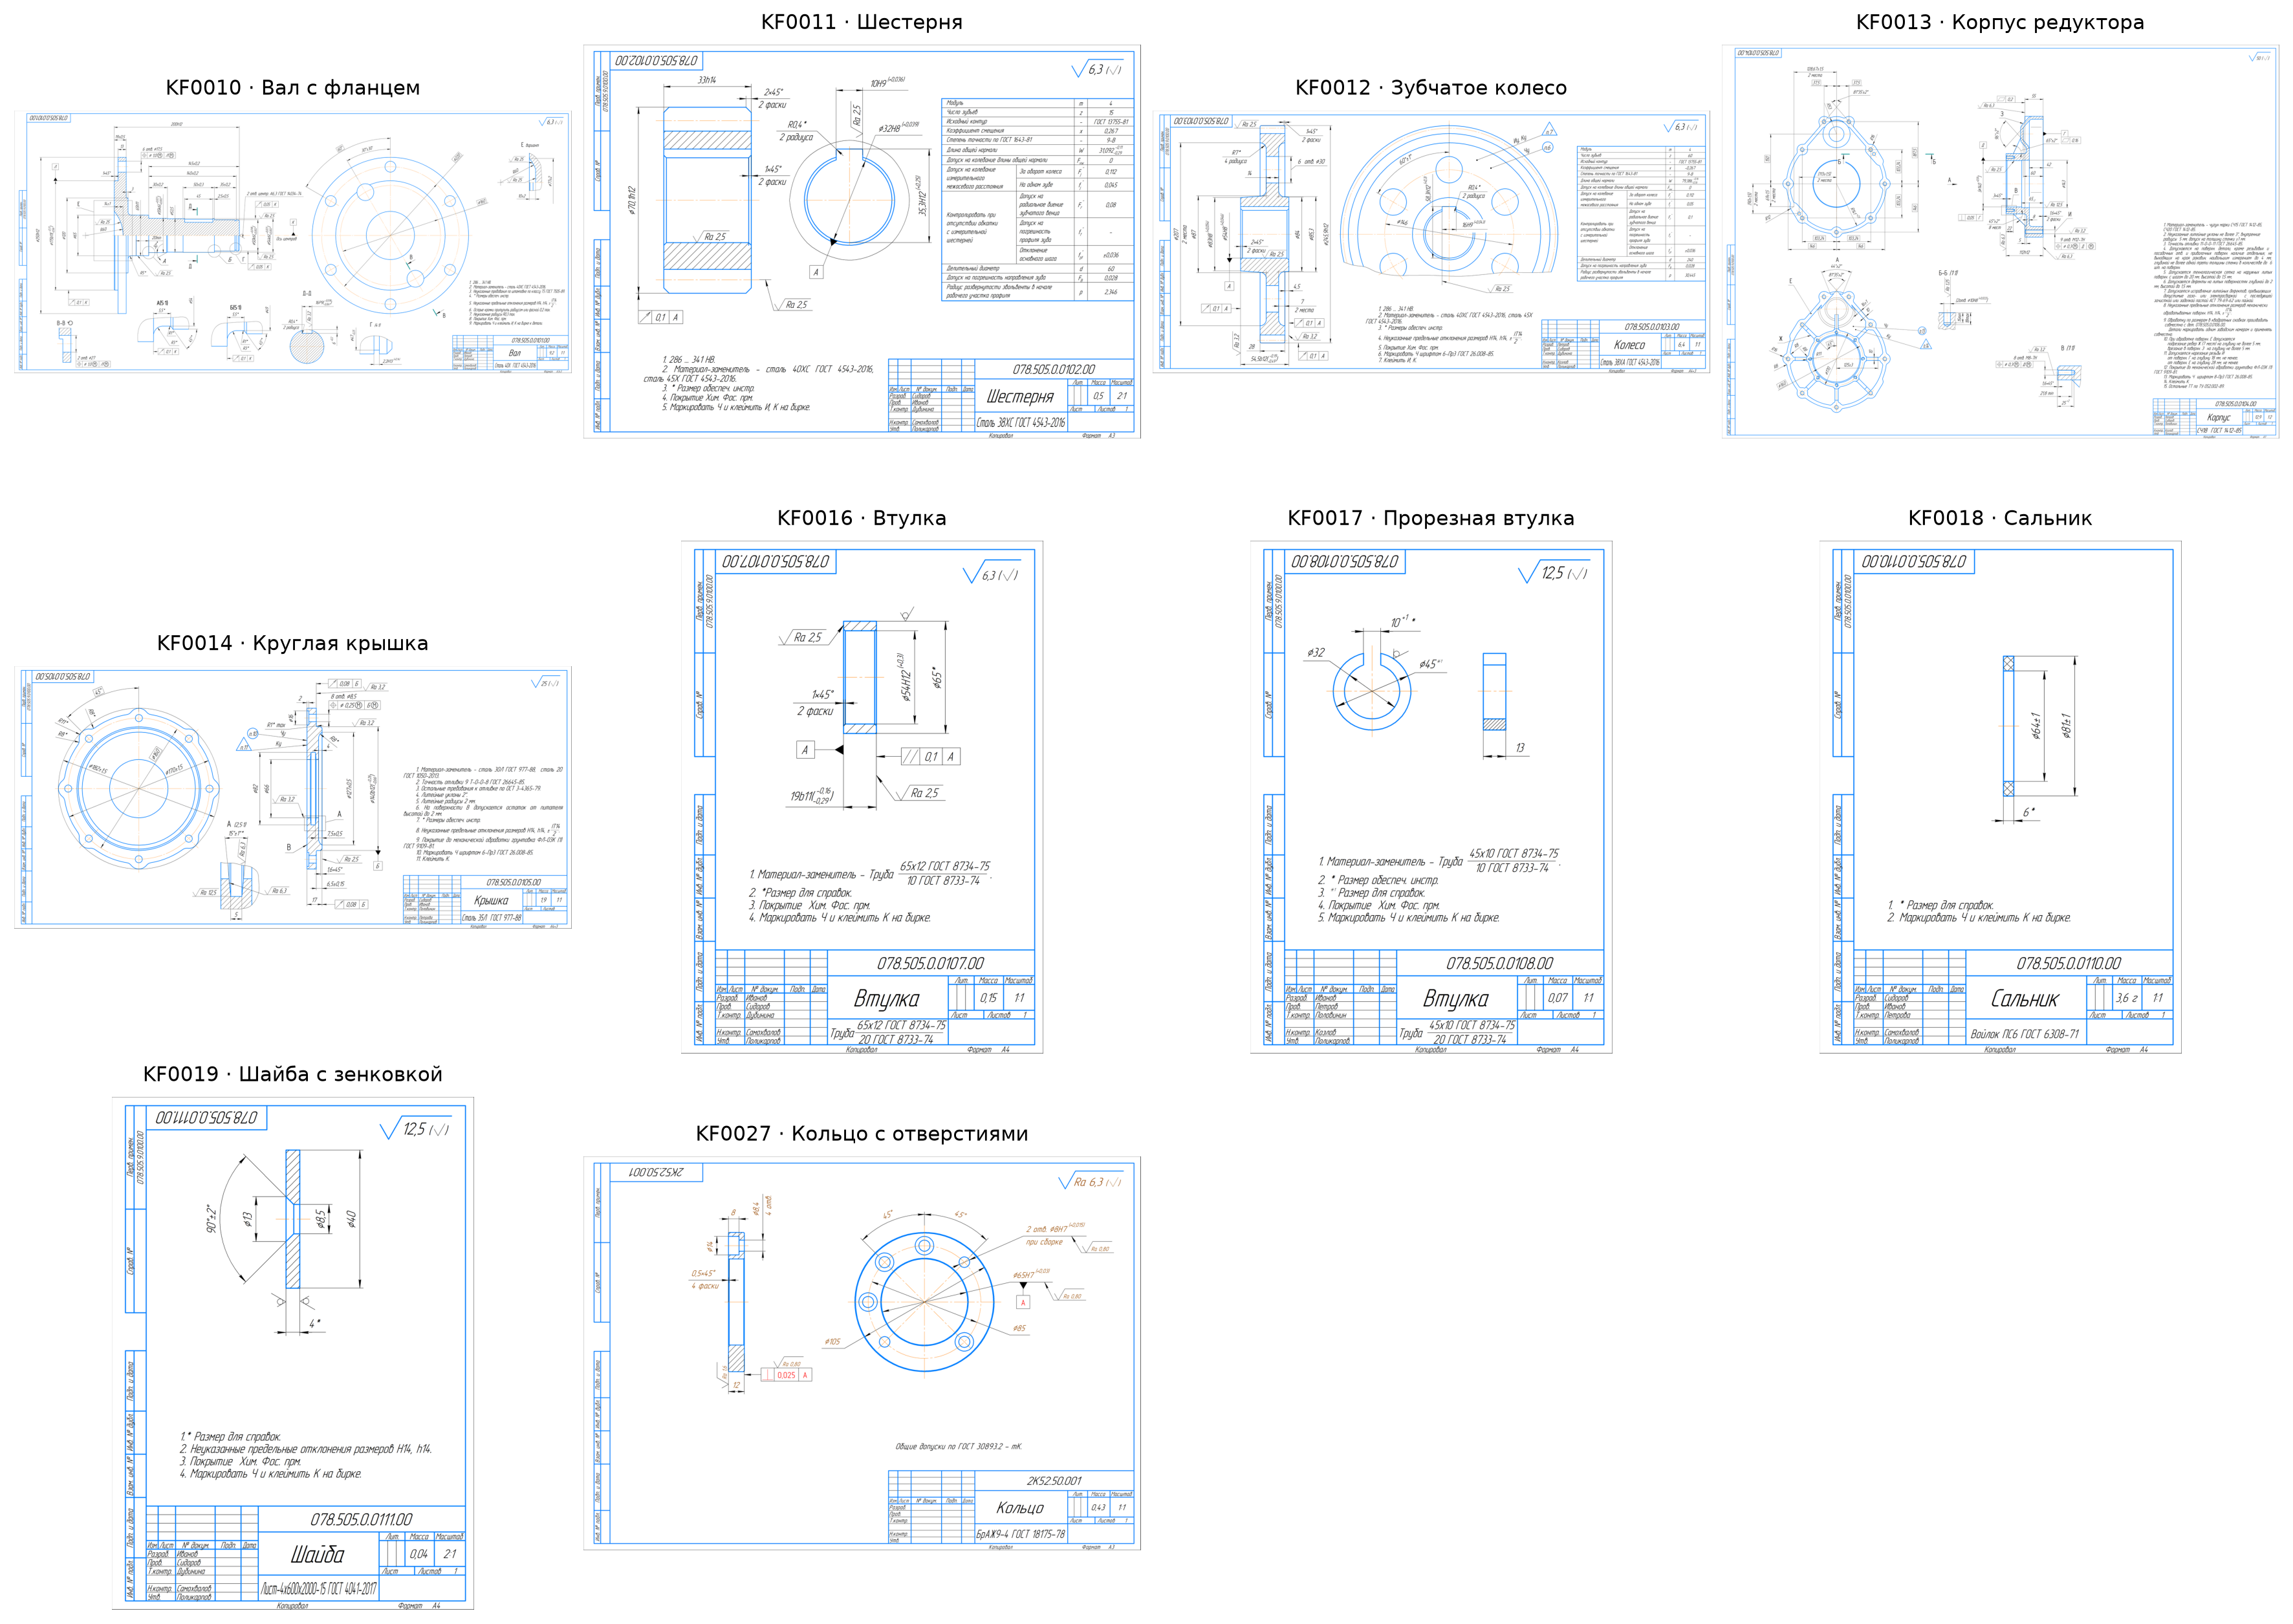

Оригиналы: [KF0010](../data/input/KF0010.png) · [KF0011](../data/input/KF0011.png) · [KF0012](../data/input/KF0012.png) · [KF0013](../data/input/KF0013.png) · [KF0014](../data/input/KF0014.png) · [KF0016](../data/input/KF0016.png) · [KF0017](../data/input/KF0017.png) · [KF0018](../data/input/KF0018.png) · [KF0019](../data/input/KF0019.png) · [KF0027](../data/input/KF0027.png)

In [2]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11.5), dpi=220, layout="constrained")
for axis in axes.flat:
    axis.set_axis_off()
for axis, (key, item) in zip(axes.flat, items.items(), strict=False):
    with Image.open(DATA / item["input_png"]["path"]) as picture:
        preview = picture.copy()
        preview.thumbnail((1600, 1600), Image.Resampling.LANCZOS)
    axis.imshow(preview)
    axis.set_title(f"{key} · {item['name']}", fontsize=10, pad=8)
plt.show()
display(Markdown("Оригиналы: " + " · ".join(
    f"[{key}](../data/{item['input_png']['path']})" for key, item in items.items()
)))

## 2. Размер файла и объём изображения — разные вещи

Проверяем формат и полное декодирование каждого PNG. Считаем разрешение, размер файла
и долю небелых пикселей: яркость ниже 245 из 255 после перевода в оттенки серого.
В эту долю входят контуры, текст, штриховка и рамка; это **не площадь детали**
и не автоматическая оценка читаемости размеров.

,"Разрешение, пикс.",Мегапиксели,"PNG, КиБ","Небелые пиксели, %",Ориентация
Деталь,,,,,
KF0010,10525 × 4962,52.23,785.76,3.28,альбомная
KF0011,4962 × 3509,17.41,372.29,5.66,альбомная
KF0012,7442 × 3509,26.11,569.22,5.40,альбомная
KF0013,9934 × 7017,69.71,1047.50,3.29,альбомная
KF0014,7442 × 3509,26.11,538.73,4.79,альбомная
KF0016,2481 × 3509,8.71,187.42,6.12,книжная
KF0017,2481 × 3509,8.71,178.43,5.96,книжная
KF0018,2481 × 3509,8.71,139.56,4.96,книжная
KF0019,2481 × 3509,8.71,166.74,5.71,книжная


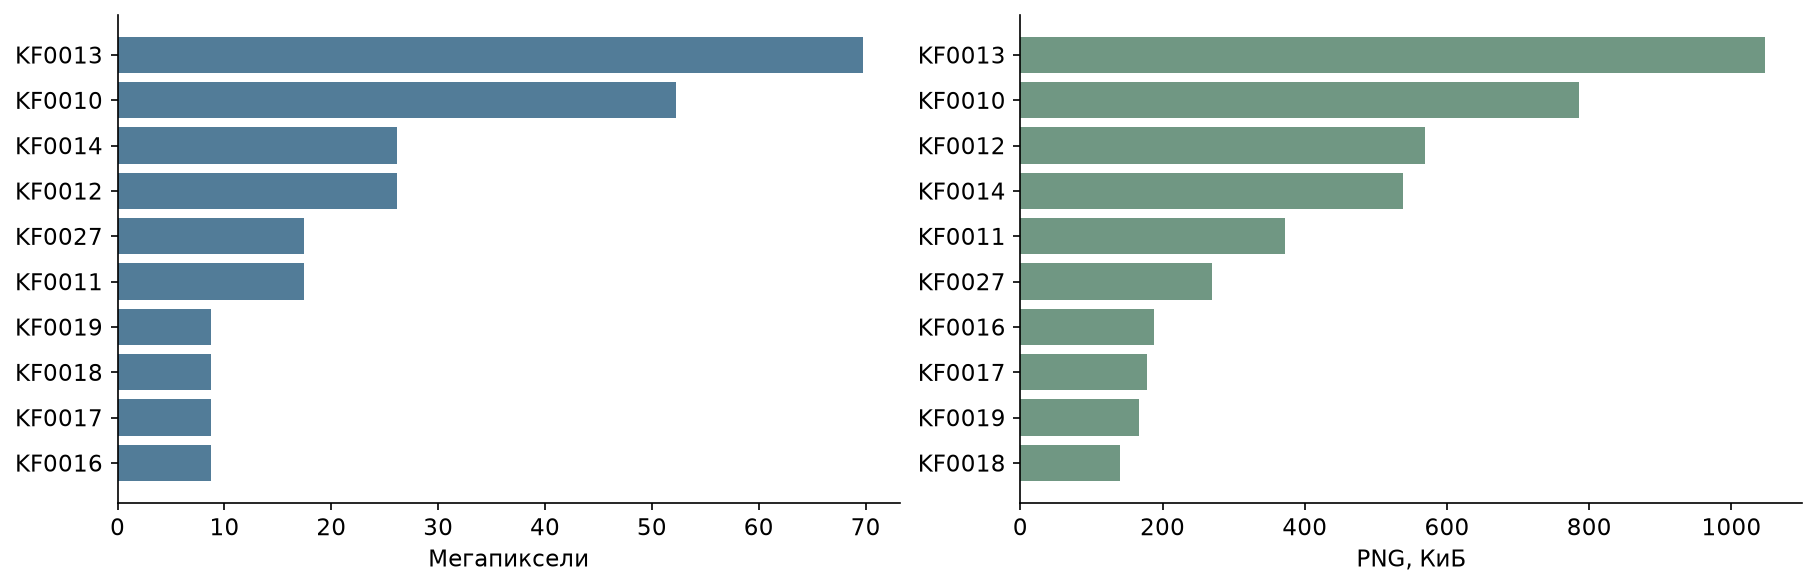

In [3]:
image_rows = []
for key, item in items.items():
    path = DATA / item["input_png"]["path"]
    with Image.open(path) as picture:
        picture.load()
        assert picture.format == "PNG" and picture.mode == "RGB"
        width, height = picture.size
        ink_percent = float((np.asarray(picture.convert("L")) < 245).mean() * 100)
    image_rows.append({
        "Деталь": key, "Разрешение, пикс.": f"{width} × {height}",
        "Мегапиксели": width * height / 1_000_000,
        "PNG, КиБ": path.stat().st_size / 1024,
        "Небелые пиксели, %": ink_percent,
        "Ориентация": "альбомная" if width > height else "книжная",
    })
images = pd.DataFrame(image_rows).set_index("Деталь")
display(images.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for axis, column, color in zip(axes, ["Мегапиксели", "PNG, КиБ"], ["#527c98", "#709783"], strict=False):
    values = images[column].sort_values()
    axis.barh(values.index, values, color=color)
    axis.set_xlabel(column)
    axis.spines[["top", "right"]].set_visible(False)
plt.show()

In [26]:
largest = images["Мегапиксели"].nlargest(2)
display(Markdown(
    f"**Наблюдения.** Все {len(images)} входов — читаемые RGB PNG. "
    f"Разрешение меняется от {images['Мегапиксели'].min():.1f} до "
    f"{images['Мегапиксели'].max():.1f} Мп, а файлы занимают всего "
    f"{images['PNG, КиБ'].min():.0f}–{images['PNG, КиБ'].max():.0f} КиБ. "
    f"Самые большие растры — {', '.join(largest.index)}. "
    f"Небелые пиксели занимают {images['Небелые пиксели, %'].min():.1f}–"
    f"{images['Небелые пиксели, %'].max():.1f}% листа.\n\n"
))

**Наблюдения.** Все 10 входов — читаемые RGB PNG. Разрешение меняется от 8.7 до 69.7 Мп, а файлы занимают всего 140–1048 КиБ. Самые большие растры — KF0013, KF0010. Небелые пиксели занимают 3.3–6.1% листа.



Однородный белый фон хорошо сжимается: небольшой PNG может требовать много памяти после декодирования. Размер в байтах сам по себе не характеризует нагрузку обработки. При уменьшении листа мелкие надписи и знаки допусков теряют читаемость; предобработку нужно учитывать в протоколе, сохраняя исходные PNG.

**Что нужно извлекать из этих изображений.** На одном листе совмещены разные виды,
разрезы, размерные выноски и служебные надписи. Размеры нельзя восстанавливать по
масштабу картинки: нужны числовые значения и связь между видами. Контуры, осевые линии
и надписи используют разные цвета; перевод в чёрно-белый вид может убрать полезные различия.

| Наблюдение в наборе | Почему это важно для восстановления |
|---|---|
| Зубчатые детали KF0011 и KF0012 | Венец задаётся в том числе таблицей параметров, а не только нарисованным контуром. |
| Вал KF0010, корпус KF0013, крышка KF0014 | Нужно согласовать ступени, отверстия, глубины и несколько видов. Одного внешнего силуэта недостаточно. |
| Втулки, сальник, шайба и кольцо | Простая общая форма всё равно содержит пазы, фаски, зенковку или отверстия. |
| Допуски и справочные размеры | Номинал, интервал допуска и размер со звёздочкой имеют разный смысл. |

Это качественный обзор листов и сохранённых проверок пар, не результат OCR.
Полнота всех размерных цепей не доказана: часть геометрии задаётся таблицами и условными
обозначениями. Масок видов, распознанного текста и полной разметки размеров в наборе нет.

## 3. Выход: эталонные STL

STL хранит поверхность из треугольников. В нём нет дерева построения, семантики отверстий
или единиц измерения — **миллиметры заданы описью**. Анализируем именно подготовленные
сетки `data/target`, с которыми затем сравнивается результат генератора.

Общая система координат: основная ось вдоль +Z, задний торец около Z=0.
Положение главной оси и повороты сохранены при подготовке эталонов.
Наличие общей оси не означает осевую симметрию: её нарушают пазы, отверстия и форма корпуса.

In [5]:
assert manifest["coordinates"]["units"] == "mm"
meshes, mesh_rows = {}, []
for key, item in items.items():
    target = item["target_mesh"]
    mesh = trimesh.load_mesh(DATA / target["path"], process=True)
    assert isinstance(mesh, trimesh.Trimesh) and np.isfinite(mesh.vertices).all()
    meshes[key] = mesh
    x, y, z = mesh.extents
    mesh_rows.append({
        "Деталь": key, "X, мм": x, "Y, мм": y, "Z, мм": z,
        "Объём, см³": mesh.volume / 1000, "Треугольники": len(mesh.faces),
        "Замкнута": "да" if mesh.is_watertight else "нет",
        "Корректный объём": "да" if mesh.is_volume else "нет",
        "Компоненты": mesh.body_count,
        "Z минимум, мм": mesh.bounds[0, 2],
    })
models = pd.DataFrame(mesh_rows).set_index("Деталь")
display(models.drop(columns=["Z минимум, мм"]).round(2))
print(f"Максимальное отклонение заднего торца от Z=0: {models['Z минимум, мм'].abs().max():.2g} мм.")

,"X, мм","Y, мм","Z, мм","Объём, см³",Треугольники,Замкнута,Корректный объём,Компоненты
Деталь,,,,,,,,
KF0010,250.00,250.00,200.00,1173.10,51902,да,да,1
KF0011,69.85,69.47,33.00,71.36,8680,да,да,1
KF0012,245.86,245.86,54.50,820.75,77640,да,да,1
KF0013,323.99,365.49,112.00,1789.96,227384,да,да,1
KF0014,182.00,182.00,17.00,235.29,39098,да,да,1
KF0016,65.00,64.99,19.00,19.35,2526,да,да,1
KF0017,45.00,44.43,13.00,9.36,924,да,да,1
KF0018,81.98,82.00,7.11,11.92,2750,да,да,1
KF0019,40.00,39.99,4.00,4.72,2016,да,да,1


Максимальное отклонение заднего торца от Z=0: 5.6e-08 мм.


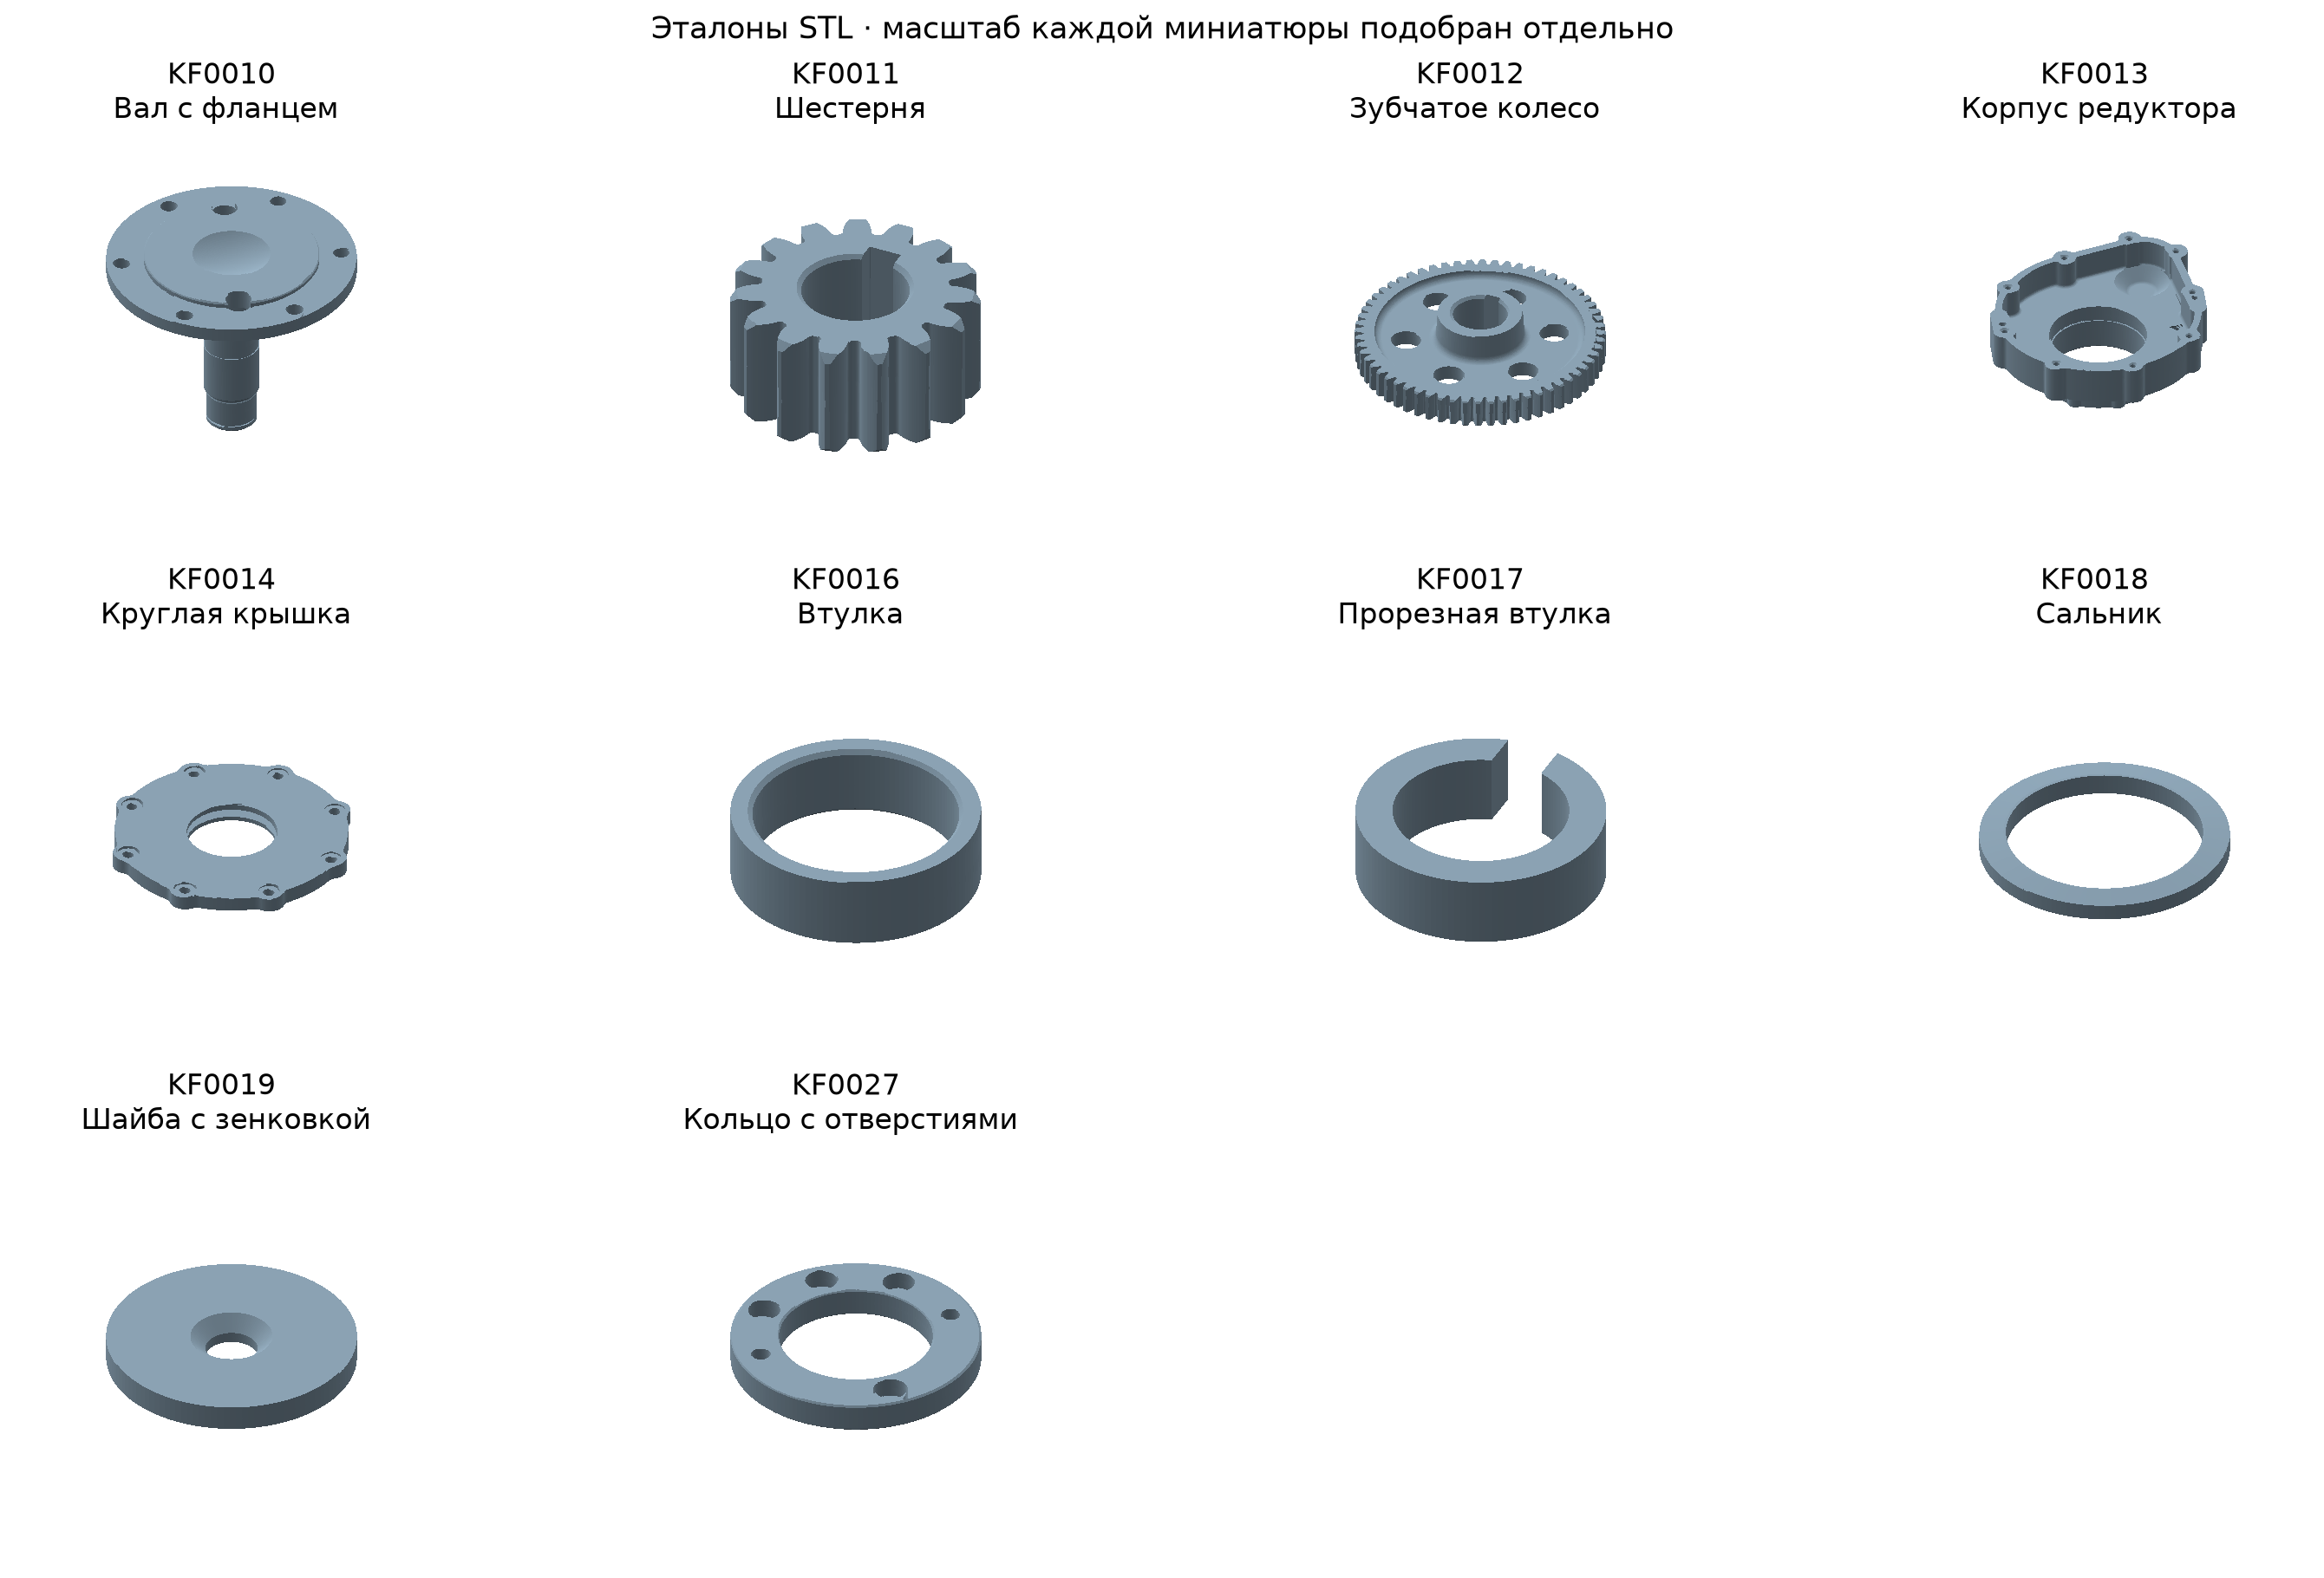

In [23]:
fig = plt.figure(figsize=(16, 10), dpi=180, layout="constrained")
elevation, azimuth = np.deg2rad([35, -65])
direction = [np.cos(elevation) * np.cos(azimuth), np.cos(elevation) * np.sin(azimuth), np.sin(elevation)]
for index, (key, mesh) in enumerate(meshes.items(), start=1):
    axis = fig.add_subplot(3, 4, index, projection="3d")
    triangles = mesh.triangles
    # Убираем обратные стороны только при отрисовке; исходная сетка не меняется.
    visible = mesh.face_normals @ direction > 0
    axis.add_collection3d(Poly3DCollection(
        triangles[visible], facecolors="#9bb5c8", linewidths=0,
        antialiased=False, shade=True, lightsource=LightSource(315, 45),
    ))
    center = mesh.bounds.mean(axis=0)
    radius = mesh.extents.max() / 2
    axis.set(xlim=(center[0] - radius, center[0] + radius),
             ylim=(center[1] - radius, center[1] + radius),
             zlim=(center[2] - radius, center[2] + radius), title=f'{key} \n{items[key]["name"]}')
    axis.set_box_aspect((1, 1, 1))
    axis.set_proj_type("ortho")
    axis.view_init(elev=35, azim=-65)
    axis.set_axis_off()
fig.suptitle("Эталоны STL · масштаб каждой миниатюры подобран отдельно", fontsize=14)
plt.show()

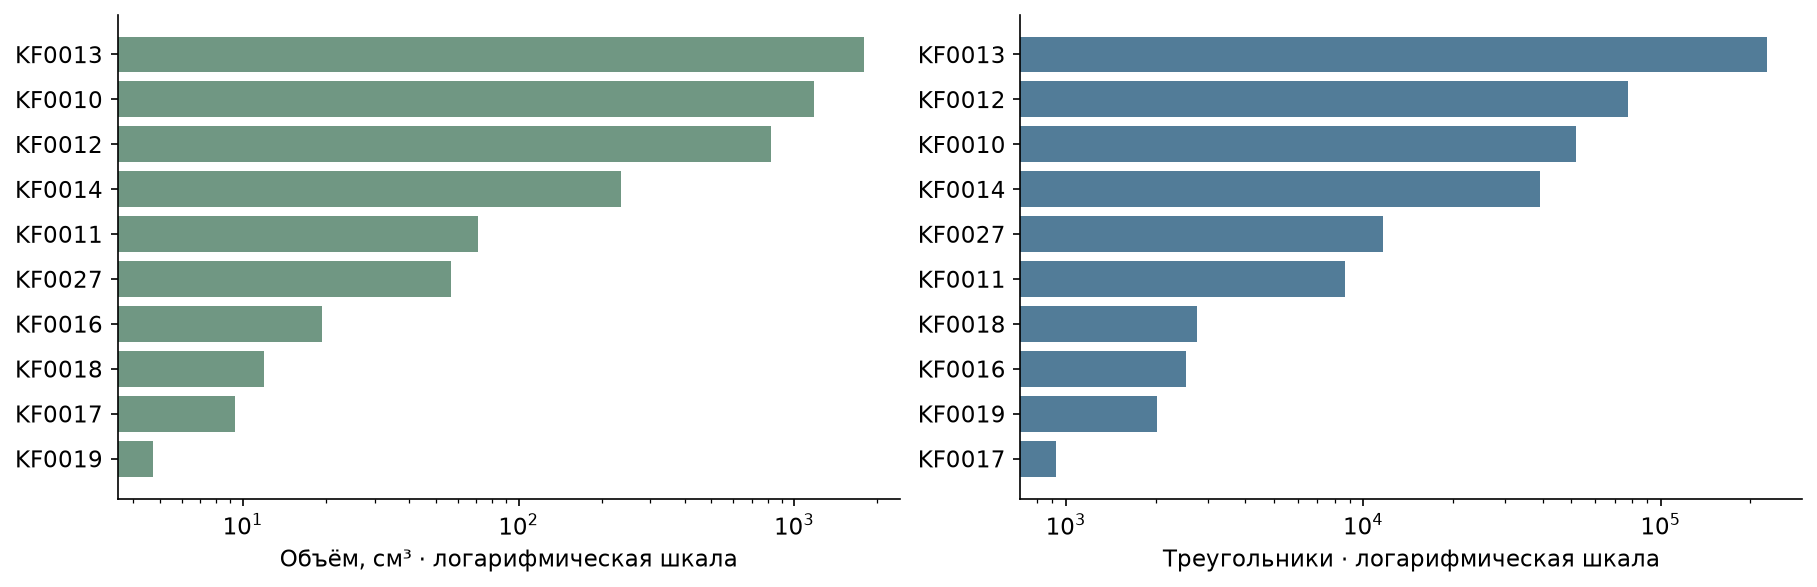

Все 10 сеток замкнуты: **10/10**; корректный объём имеют **10/10**. Число связных компонентов: 1–1. Объёмы отличаются в **379 раз**, число треугольников — от **924** до **227,384**.



In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for axis, column, color in zip(axes, ["Объём, см³", "Треугольники"], ["#709783", "#527c98"], strict=False):
    values = models[column].sort_values()
    axis.barh(values.index, values, color=color)
    axis.set_xscale("log")
    axis.set_xlabel(column + " · логарифмическая шкала")
    axis.spines[["top", "right"]].set_visible(False)
plt.show()

display(Markdown(
    f"Все {len(models)} сеток замкнуты: **{(models['Замкнута'] == 'да').sum()}/{len(models)}**; "
    f"корректный объём имеют **{(models['Корректный объём'] == 'да').sum()}/{len(models)}**. "
    f"Число связных компонентов: {models['Компоненты'].min()}–{models['Компоненты'].max()}. "
    f"Объёмы отличаются в **{models['Объём, см³'].max() / models['Объём, см³'].min():.0f} раз**, "
    f"число треугольников — от **{models['Треугольники'].min():,}** "
    f"до **{models['Треугольники'].max():,}**.\n\n"
))

Сетки пригодны для геометрического сравнения. Замкнутость подтверждает техническую целостность поверхности, но не соответствие чертежу. Число треугольников зависит от кривизны и настроек выгрузки: это не число конструктивных элементов и не оценка сложности задания. При оценке детали должны иметь одинаковый вес, иначе крупные или густо разбитые на треугольники модели будут определять итог.

## 4. Где эталон не равен чертежу

Контрольная сумма подтверждает сохранность файла, но не правильность пары.
При подготовке набора проверялись ключевые размеры и исполнение; сплошной проверки
каждого допуска и всех поверхностей не было. Сохраняем обнаруженные различия,
не исправляя эталоны под входные картинки.

In [29]:
counts = pd.Series([item["pair_validation"] for item in items.values()]).value_counts()
display(counts.rename_axis("Статус проверки").to_frame("Пар"))

,Пар
Статус проверки,
Проверены ключевые размеры,5
Есть известные различия,3
Пройдена сохранённая проверка пары,2


| Пара | На чертеже | В исходной модели / эталоне |
|---|---|---|
| [KF0011](../data/input/KF0011.png) | Отверстие Ø32 | Ø30,6 |
| [KF0012](../data/input/KF0012.png) | Отверстие Ø54H8; наружный Ø245h12 | Отверстие Ø55; наружный габарит 245,864 мм |
| [KF0018](../data/input/KF0018.png) | Плоское кольцо; справочная толщина 6* мм | Конические торцы; осевой габарит около 7,10644 мм |

У KF0018 диаметры Ø65 и Ø82 лежат на границах заданных диапазонов Ø64±1 и Ø81±1;
это **не выход за допуск**. Разница справочной толщины сама по себе не доказывает
производственный брак. Сопоставления и ограничения сохранены в [manifest](../data/manifest.json)
в поле `limitations`. Подробные проверки и исходные выгрузки сохранены в локальном архиве;
для этого анализа достаточно PNG, готовых STL и manifest.

Следствие для эксперимента: модель, точно следующая PNG, может не получить идеальные
IoU и F-score относительно выбранного STL. Ошибки исходной пары нужно отделять от
ошибок восстановления; три пары не следует молча исключать из среднего.

## 5. Выводы и ограничения эксперимента

1. **Вход неоднороден по разрешению и содержанию.** От простых колец переходим к
   ступенчатому валу, зубчатым колёсам и корпусу. Одного силуэта недостаточно:
   нужны размеры, виды, разрезы и таблицы. Уменьшение изображений и увеличенные фрагменты
   стоит сравнивать как отдельные способы подготовки входа.
2. **Выход позволяет обойтись без CAD-приложения.** STL можно читать, показывать
   и проверять обычными Python-библиотеками. Единицы и положение детали должны быть
   зафиксированы отдельно; центровка по габаритному ящику не заменяет главную ось детали.
3. **Простота рецепта ограничивает достижимую точность.** Фаски, скругления, зенковки,
   зубчатые и литейные поверхности присутствуют в эталонах. Круговые и многоугольные
   выдавливания могут их лишь приближать. Это ограничение представления результата,
   а не обязательно ошибка чтения чертежа.
4. **У трёх пар есть известные различия входа и эталона.** Поэтому геометрические метрики
   нужно сопровождать разбором причин отклонений. Отсутствие записи о различиях у остальных
   пар не равнозначно полной экспертизе чертежа.
5. **Десять объектов — узкая рабочая выборка.** Девять происходят из примера редуктора,
   один — из примера вала. Папка источника не равна семейству деталей: близкие варианты
   нужно отдельно группировать при будущем разделении на отладку и валидацию.
   Все текущие объекты — валидация, включая KF0011. Набор не является независимым тестом;
   выводов о всём корпусе и устойчивости повторных запусков по нему не делаем.

Этот EDA устанавливает свойства входов, пригодность эталонных сеток и ограничения данных.
Качество генератора проверяется отдельным экспериментом.